In [1]:
import pandas as pd 
import numpy as np
import warnings
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

In [2]:
pd.__version__ 

'2.3.3'

In [3]:
df = pd.read_csv("C:\\Users\\dell\\Desktop\\anaconda\\Pima Indians Diabetes.csv") 

In [4]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [5]:
df = df.sample(frac=1,random_state = 20) 
df = df.reset_index(drop=True) 

In [6]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0
...,...,...,...,...,...,...,...,...,...
763,5,85,74,22,0,29.0,1.224,32,1
764,7,142,60,33,190,28.8,0.687,61,0
765,2,108,62,32,56,25.2,0.128,21,0
766,4,114,64,0,0,28.9,0.126,24,0


In [7]:
df_train = df.iloc[:614].copy(deep =True)
df_val = df.iloc[614:691].copy(deep =True).reset_index(drop=True) 
df_test = df.iloc[691:].copy(deep =True).reset_index(drop=True) 

In [8]:
print(df_train.shape , df_val.shape , df_test.shape)

(614, 9) (77, 9) (77, 9)


In [9]:
print(df.shape) 

(768, 9)


#8
Pregnancies: تعداد دفعات بارداری این ستون نشان می‌دهد که یک زن چند بار باردار شده است.
Glucose: سطح گلوکز خون (قند خون). این اندازه‌گیری معمولاً پس از ناشتا بودن انجام می‌شود و می‌تواند نشان‌دهنده مشکلاتی مانند دیابت باشد.
BloodPressure: فشار خون دیاستولیک (عدد پایینی فشار خون). این مقدار بر حسب میلی‌متر جیوه (mmHg) است.
SkinThickness: ضخامت چین پوستی سه سر بازو. این اندازه‌گیری می‌تواند به تخمین میزان چربی بدن کمک کند.
Insulin: سطح انسولین سرم. انسولین هورمونی است که به تنظیم قند خون کمک می‌کند.
BMI: شاخص توده بدنی. این شاخص با تقسیم وزن (به کیلوگرم) بر مجذور قد (به متر) محاسبه می‌شود و معیاری برای ارزیابی وزن نسبت به قد است.
DiabetesPedigreeFunction: تابع شجره‌نامه دیابت. این یک معیار ژنتیکی است که احتمال ابتلا به دیابت را بر اساس سابقه خانوادگی فرد ارزیابی می‌کند. مقدار بالاتر نشان‌دهنده ریسک بالاتر است.
Age: سن فرد (بر حسب سال).
Outcome: نتیجه تشخیص. این ستون نشان می‌دهد که آیا فرد به دیابت مبتلا است یا خیر. مقدار ‘0’ به معنی عدم ابتلا به دیابت و مقدار ‘1’ به معنی ابتلا به دیابت است.

In [10]:
df_train.head() 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0


In [11]:
df_train.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               614 non-null    int64  
 1   Glucose                   614 non-null    int64  
 2   BloodPressure             614 non-null    int64  
 3   SkinThickness             614 non-null    int64  
 4   Insulin                   614 non-null    int64  
 5   BMI                       614 non-null    float64
 6   DiabetesPedigreeFunction  614 non-null    float64
 7   Age                       614 non-null    int64  
 8   Outcome                   614 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 43.3 KB


اولین اندیس:1
آخرین اندیس: 768
تعداد کل ردیف‌ها: 768

In [12]:
df_train.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000,614.000000
mean,3.724756,121.161238,69.087948,20.750814,81.701954,32.113192,0.474873,32.874593,0.366450
std,3.301708,32.848335,19.830326,16.007180,115.837291,7.863379,0.336785,11.437278,0.482227
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,0.000000,0.000000,27.400000,0.245250,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,36.000000,32.350000,0.375500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,32.000000,130.000000,36.600000,0.621500,40.000000,1.000000
max,15.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,72.000000,1.000000


In [13]:
df.head(10) 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0
5,5,109,62,41,129,35.8,0.514,25,1
6,5,97,76,27,0,35.6,0.378,52,1
7,1,140,74,26,180,24.1,0.828,23,0
8,2,128,64,42,0,40.0,1.101,24,0
9,7,81,78,40,48,46.7,0.261,42,0


In [14]:
df.tail(3)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
765,2,108,62,32,56,25.2,0.128,21,0
766,4,114,64,0,0,28.9,0.126,24,0
767,9,165,88,0,0,30.4,0.302,49,1


In [15]:
df.iloc[:, 4:7]

,Insulin,BMI,DiabetesPedigreeFunction
0,0,32.4,0.272
1,175,25.8,0.587
2,0,37.3,0.238
3,0,27.8,0.237
4,120,27.4,0.515
...,...,...,...
763,0,29.0,1.224
764,190,28.8,0.687
765,56,25.2,0.128
766,0,28.9,0.126


In [16]:
df_train.iloc[:20]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0
5,5,109,62,41,129,35.8,0.514,25,1
6,5,97,76,27,0,35.6,0.378,52,1
7,1,140,74,26,180,24.1,0.828,23,0
8,2,128,64,42,0,40.0,1.101,24,0
9,7,81,78,40,48,46.7,0.261,42,0


In [17]:
df.iloc[14:35, 1:5]

,Glucose,BloodPressure,SkinThickness,Insulin
14,106,64,35,119
15,72,78,25,0
16,97,64,19,82
17,102,64,46,78
18,136,74,50,204
19,115,0,0,0
20,108,62,10,278
21,106,60,24,0
22,130,64,0,0
23,130,70,13,105


In [18]:
df_train["Pregnancies"] 

0      10
1       5
2       3
3       8
4       0
       ..
609     3
610     2
611     7
612    12
613     4
Name: Pregnancies, Length: 614, dtype: int64

In [19]:
df_train[["BMI","Insulin","Glucose"]] 

,BMI,Insulin,Glucose
0,32.4,0,108
1,25.8,175,166
2,37.3,0,96
3,27.8,0,110
4,27.4,120,126
...,...,...,...
609,24.7,115,96
610,21.1,49,96
611,37.2,105,102
612,30.0,105,100


In [20]:
df_train.loc[df_train["Age"] <= 50]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
2,3,96,78,39,0,37.3,0.238,40,0
4,0,126,86,27,120,27.4,0.515,21,0
5,5,109,62,41,129,35.8,0.514,25,1
7,1,140,74,26,180,24.1,0.828,23,0
...,...,...,...,...,...,...,...,...,...
609,3,96,56,34,115,24.7,0.944,39,0
610,2,96,68,13,49,21.1,0.647,26,0
611,7,102,74,40,105,37.2,0.204,45,0
612,12,100,84,33,105,30.0,0.488,46,0


In [21]:
df_train.loc[df_train["Pregnancies"] == 0]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
4,0,126,86,27,120,27.4,0.515,21,0
13,0,102,78,40,90,34.5,0.238,24,0
17,0,102,64,46,78,40.6,0.496,21,0
25,0,102,86,17,105,29.3,0.695,27,0
30,0,162,76,56,100,53.2,0.759,25,1
...,...,...,...,...,...,...,...,...,...
591,0,126,84,29,215,30.7,0.520,24,0
593,0,117,0,0,0,33.8,0.932,44,0
599,0,101,64,17,0,21.0,0.252,21,0
607,0,177,60,29,478,34.6,1.072,21,1


In [22]:
df_train.loc[(df_train["BloodPressure"] >= 70) & (df_train["BloodPressure"] <= 100)]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0
6,5,97,76,27,0,35.6,0.378,52,1
...,...,...,...,...,...,...,...,...,...
602,8,188,78,0,0,47.9,0.137,43,1
603,4,173,70,14,168,29.7,0.361,33,1
608,0,131,88,0,0,31.6,0.743,32,1
611,7,102,74,40,105,37.2,0.204,45,0


In [23]:
df_train.loc[(df_train["Age"] > 50) & (df_train["BMI"] >= 25) & (df_train["BMI"] <= 30)]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
1,5,166,72,19,175,25.8,0.587,51,1
3,8,110,76,0,0,27.8,0.237,58,0
26,1,135,54,0,0,26.7,0.687,62,0
40,8,194,80,0,0,26.1,0.551,67,0
136,4,132,86,31,0,28.0,0.419,63,0
144,6,166,74,0,0,26.6,0.304,66,0
213,7,136,74,26,135,26.0,0.647,51,0
228,0,105,84,0,0,27.9,0.741,62,1
264,10,162,84,0,0,27.7,0.182,54,0
357,2,108,80,0,0,27.0,0.259,52,1


In [24]:
df_train[(df_train["Age"] >= 20) & (df_train["Age"] <= 30)].shape[0]

339

In [25]:
df_train.loc[df_train["Outcome"] == 1]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
5,5,109,62,41,129,35.8,0.514,25,1
6,5,97,76,27,0,35.6,0.378,52,1
10,1,168,88,29,0,35.0,0.905,52,1
...,...,...,...,...,...,...,...,...,...
602,8,188,78,0,0,47.9,0.137,43,1
603,4,173,70,14,168,29.7,0.361,33,1
607,0,177,60,29,478,34.6,1.072,21,1
608,0,131,88,0,0,31.6,0.743,32,1


In [26]:
#part2.1,2
df_train.isnull().sum()
df_train.isnull().sum().sum()

np.int64(0)

در این دیتاست مقدار Null وجود ندارد
بنابراین هیچ سطر یا ستونی حذف نمی‌شود
در دیتاست Pima معمولاً داده‌های گمشده به صورت 0 ذخیره شده‌اند نه NaN، بنابراین در بخش پاکسازی نیازی به حذف سطر یا ستون نیست و اصلاح این مقادیر در بخش Feature Engineering انجام می‌شود.

In [27]:
# سوال 4
df_train = df_train.reset_index(drop=True)

In [28]:
# سوال 5
df_train.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [29]:
# سوال 6
df_train.corr()['Outcome']

Pregnancies                 0.212018
Glucose                     0.482148
BloodPressure               0.079702
SkinThickness               0.046931
Insulin                     0.107209
BMI                         0.274659
DiabetesPedigreeFunction    0.166446
Age                         0.273363
Outcome                     1.000000
Name: Outcome, dtype: float64

In [30]:
# سوال 7
df_train.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [31]:
# بخش3
# سوال 1
(df_train == 0).sum()

Pregnancies                  94
Glucose                       5
BloodPressure                30
SkinThickness               178
Insulin                     297
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
Outcome                     389
dtype: int64

In [32]:
# سوال 2,3
df_train.loc[df_train["Glucose"]!=0,"Glucose"].median()

117.0

In [33]:
# سوال 4
train_median_dict={"Glucose":df_train.loc[df_train["Glucose"]!=0,"Glucose"].median(),
                "BloodPressure":df_train.loc[df_train["BloodPressure"]!=0,"BloodPressure"].median(),
                "SkinThickness":df_train.loc[df_train["SkinThickness"]!=0,"SkinThickness"].median(),
                "Insulin":df_train.loc[df_train["Insulin"]!=0,"Insulin"].median(),
                "BMI":df_train.loc[df_train["BMI"]!=0,"BMI"].median()}

In [122]:
# سوال 5
for k,v in train_median_dict.items():
    df_train.loc[df_train[k]==0,k]=v

In [123]:
# سوال 6
df_train.to_csv(
    'Pima_Diabetes_Cleaned.csv',
    index=False
)

In [124]:
#part4
#سوال3
df_train["Outcome"].value_counts()

Outcome
0    389
1    225
Name: count, dtype: int64

In [34]:
#سوال4
df_train["Pregnancies"].min(),df_train["Pregnancies"].max()

(0, 15)

In [35]:
#سوال5
bins = [0, 1, 3, 5, 10, 20]

labels = ["0-1", "1-3", "3-5", "5-10", "10-20"]

df["G_P"] = pd.cut(
    df["Pregnancies"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=False
)
print(df["G_P"].value_counts().sort_index())

G_P
0-1      111
1-3      238
3-5      143
5-10     218
10-20     58
Name: count, dtype: int64


In [36]:
#سوال6
df.groupby("G_P")["Outcome"].value_counts()

G_P    Outcome
0-1    0           73
       1           38
1-3    0          190
       1           48
3-5    0           93
       1           50
5-10   0          116
       1          102
10-20  1           30
       0           28
Name: count, dtype: int64

In [37]:
#سوال7
def ratio(x):

    return x.value_counts(normalize=True)

df.groupby("G_P")["Outcome"].apply(ratio)

G_P     
0-1    0    0.657658
       1    0.342342
1-3    0    0.798319
       1    0.201681
3-5    0    0.650350
       1    0.349650
5-10   0    0.532110
       1    0.467890
10-20  1    0.517241
       0    0.482759
Name: Outcome, dtype: float64

#سوال8
با افزایش تعداد بارداری، نسبت افراد مبتلا به دیابت نیز بیشتر می‌شود. بنابراین بین تعداد بارداری و احتمال ابتلا به دیابت رابطه مثبتی مشاهده می‌شود

In [38]:
# سوال 9
df_train["Glucose"].min(),df_train["Glucose"].max()

(0, 199)

In [39]:
#سوال10
G_G = pd.qcut(df_train["Glucose"], 4)

In [40]:
# سوال 11
df_train.groupby(G_G)["Outcome"].value_counts()

Glucose         Outcome
(-0.001, 99.0]  0          148
                1           11
(99.0, 117.0]   0          112
                1           42
(117.0, 141.0]  0           87
                1           63
(141.0, 199.0]  1          109
                0           42
Name: count, dtype: int64

In [41]:
# سوال 12

def ratio(x):
    return x.value_counts(normalize=True)

df_train.groupby(G_G)["Outcome"].apply(ratio)

Glucose          
(-0.001, 99.0]  0    0.930818
                1    0.069182
(99.0, 117.0]   0    0.727273
                1    0.272727
(117.0, 141.0]  0    0.580000
                1    0.420000
(141.0, 199.0]  1    0.721854
                0    0.278146
Name: Outcome, dtype: float64

#سوال13
با افزایش مقدار Glucose، نسبت افراد مبتلا به دیابت بیشتر می‌شود؛ بنابراین بین قند خون و احتمال ابتلا به دیابت رابطه مستقیمی وجود دارد

In [42]:
# سوال 14
df_train["BloodPressure"].min(),df_train["BloodPressure"].max()

(0, 122)

In [43]:
# سوال 15

B_P = pd.cut(
    df_train["BloodPressure"],
    bins=[0,60,80,90,120]
)

In [44]:
# سوال 16

df_train.groupby(B_P)["Outcome"].value_counts()

BloodPressure  Outcome
(0, 60]        0           79
               1           18
(60, 80]       0          218
               1          131
(80, 90]       0           59
               1           47
(90, 120]      1           16
               0           15
Name: count, dtype: int64

In [45]:
# سوال 17
def diabetes_ratio(x):
    return x["Outcome"].value_counts(normalize=True)
df_train.groupby(B_P).apply(diabetes_ratio)

BloodPressure  Outcome
(0, 60]        0          0.814433
               1          0.185567
(60, 80]       0          0.624642
               1          0.375358
(80, 90]       0          0.556604
               1          0.443396
(90, 120]      1          0.516129
               0          0.483871
Name: proportion, dtype: float64

#سوال18
بیشتر افراد دارای فشار خون بالاتر، درصد بیشتری از ابتلا به دیابت را نشان می‌دهند، اما این رابطه به اندازه Glucose قوی نیست.

In [46]:
# سوال 19
df_train["SkinThickness"].min(),df_train["SkinThickness"].max()

(0, 99)

In [47]:
# سوال 20
df_train.groupby("SkinThickness")["Outcome"].value_counts()

SkinThickness  Outcome
0              0          101
               1           77
7              0            1
               1            1
8              0            2
                         ... 
54             0            1
56             1            1
60             0            1
63             1            1
99             1            1
Name: count, Length: 88, dtype: int64

In [48]:
# سوال 21
df_train.groupby("SkinThickness")["Outcome"].value_counts()

SkinThickness  Outcome
0              0          101
               1           77
7              0            1
               1            1
8              0            2
                         ... 
54             0            1
56             1            1
60             0            1
63             1            1
99             1            1
Name: count, Length: 88, dtype: int64

In [49]:
# سوال 22
df_train.groupby("SkinThickness").apply(diabetes_ratio)

SkinThickness  Outcome
0              0          0.567416
               1          0.432584
7              0          0.500000
               1          0.500000
8              0          1.000000
                            ...   
54             0          1.000000
56             1          1.000000
60             0          1.000000
63             1          1.000000
99             1          1.000000
Name: proportion, Length: 88, dtype: float64

#سوال23
با افزایش ضخامت پوست، تغییراتی در نسبت افراد مبتلا به دیابت مشاهده می‌شود، اما این رابطه نسبت به Glucose ضعیف‌تر است.

In [50]:
# سوال 24
df_train["Insulin"].min(),df_train["Insulin"].max()

(0, 846)

In [51]:
#سوال 25

def ratio(x):
    return x.value_counts(normalize=True)

G_I = pd.qcut(df_train["Glucose"], 4)

df_train.groupby(G_I)["Outcome"].apply(ratio)

Glucose          
(-0.001, 99.0]  0    0.930818
                1    0.069182
(99.0, 117.0]   0    0.727273
                1    0.272727
(117.0, 141.0]  0    0.580000
                1    0.420000
(141.0, 199.0]  1    0.721854
                0    0.278146
Name: Outcome, dtype: float64

In [52]:
# سوال 26
df_train.groupby(G_I)["Outcome"].value_counts()

Glucose         Outcome
(-0.001, 99.0]  0          148
                1           11
(99.0, 117.0]   0          112
                1           42
(117.0, 141.0]  0           87
                1           63
(141.0, 199.0]  1          109
                0           42
Name: count, dtype: int64

In [53]:
# سوال 27
def diabetes_ratio(x):
    return x["Outcome"].value_counts(normalize=True)

df_train.groupby(G_I).apply(diabetes_ratio)

Glucose         Outcome
(-0.001, 99.0]  0          0.930818
                1          0.069182
(99.0, 117.0]   0          0.727273
                1          0.272727
(117.0, 141.0]  0          0.580000
                1          0.420000
(141.0, 199.0]  1          0.721854
                0          0.278146
Name: proportion, dtype: float64

#سوال28
با افزایش مقدار انسولین، نسبت افراد مبتلا به دیابت نیز تغییر می‌کند و این متغیر می‌تواند در تشخیص دیابت مؤثر باشد.

In [54]:
# سوال 29
df_train["BMI"].min(),df_train["BMI"].max()

(0.0, 67.1)

In [55]:
#سوال30
S_T = pd.qcut(df_train["BMI"],4,duplicates="drop")

df_train.groupby(S_T)["Outcome"].value_counts()

BMI             Outcome
(-0.001, 27.4]  0          133
                1           22
(27.4, 32.35]   0           97
                1           55
(32.35, 36.6]   0           82
                1           73
(36.6, 67.1]    0           77
                1           75
Name: count, dtype: int64

In [56]:
B_M = pd.qcut(
    df_train["BMI"],
    q=4,
    duplicates="drop"
)

In [57]:
# سوال 31
df_train.groupby(B_M)["Outcome"].value_counts()

BMI             Outcome
(-0.001, 27.4]  0          133
                1           22
(27.4, 32.35]   0           97
                1           55
(32.35, 36.6]   0           82
                1           73
(36.6, 67.1]    0           77
                1           75
Name: count, dtype: int64

In [58]:
# سوال 32
df_train.groupby(B_M).apply(diabetes_ratio)

Outcome,0,1
BMI,,
"(-0.001, 27.4]",0.858065,0.141935
"(27.4, 32.35]",0.638158,0.361842
"(32.35, 36.6]",0.529032,0.470968
"(36.6, 67.1]",0.506579,0.493421


#سوال33
با افزایش BMI، درصد افراد مبتلا به دیابت نیز بیشتر می‌شود؛ بنابراین BMI یکی از عوامل مهم در ابتلا به دیابت است

In [59]:
# سوال 34
df_train["DiabetesPedigreeFunction"].min(),df_train["DiabetesPedigreeFunction"].max()

(0.078, 2.42)

In [60]:
# سوال 35

D_P = pd.qcut(df_train["DiabetesPedigreeFunction"], 4)


In [61]:
# سوال 37
df_train.groupby(D_P).apply(diabetes_ratio)

Outcome,0,1
DiabetesPedigreeFunction,,
"(0.077, 0.245]",0.733766,0.266234
"(0.245, 0.376]",0.640523,0.359477
"(0.376, 0.621]",0.647059,0.352941
"(0.621, 2.42]",0.512987,0.487013


#سوال38با افزایش مقدار Diabetes Pedigree Function، احتمال ابتلا به دیابت نیز افزایش پیدا می‌کند و این ویژگی می‌تواند در پیش‌بینی بیماری مؤثر باشد

In [62]:
# سوال 39
df_train["Age"].min(),df_train["Age"].max()

(21, 72)

In [63]:
#سوال40

bins = [20, 30, 40, 50, 100]
labels = ["20-30", "30-40", "40-50", "50-100"]

A_G = pd.cut(
    df_train["Age"],
    bins=bins,
    labels=labels
)

In [64]:
# سوال 41
df_train.groupby(A_G)["Outcome"].value_counts()

Age     Outcome
20-30   0          259
        1           80
30-40   0           67
        1           58
40-50   1           54
        0           35
50-100  1           33
        0           28
Name: count, dtype: int64

In [65]:
# سوال 42

df_train.groupby(A_G).apply(diabetes_ratio)

Age     Outcome
20-30   0          0.764012
        1          0.235988
30-40   0          0.536000
        1          0.464000
40-50   1          0.606742
        0          0.393258
50-100  1          0.540984
        0          0.459016
Name: proportion, dtype: float64

#سوال43
با افزایش سن، نسبت افراد مبتلا به دیابت نیز بیشتر می‌شود. بنابراین سن یکی از عوامل مؤثر در ابتلا به دیابت است و می‌تواند در پیش‌بینی این بیماری نقش داشته باشد.

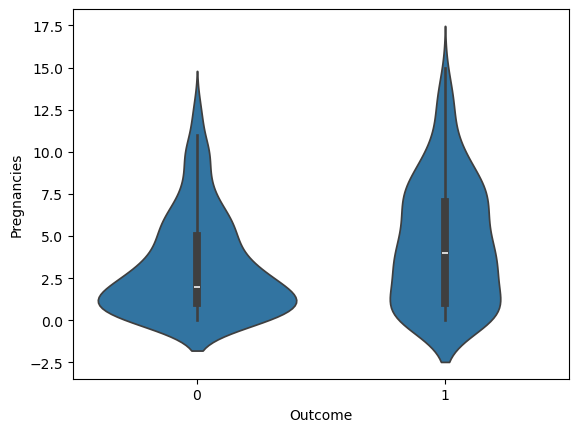

In [66]:
#part5
sns.violinplot(x="Outcome", y="Pregnancies", data=df_train)
plt.show()

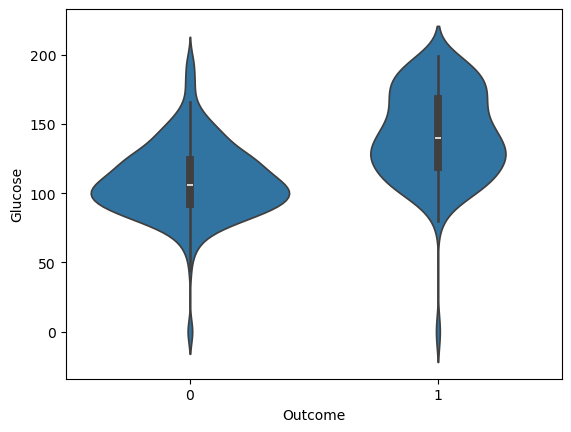

In [67]:
sns.violinplot(x="Outcome", y="Glucose", data=df_train)
plt.show()

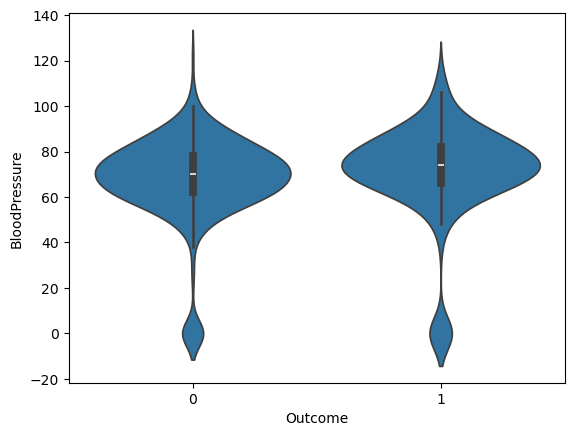

In [68]:
sns.violinplot(x="Outcome", y="BloodPressure", data=df_train)
plt.show()

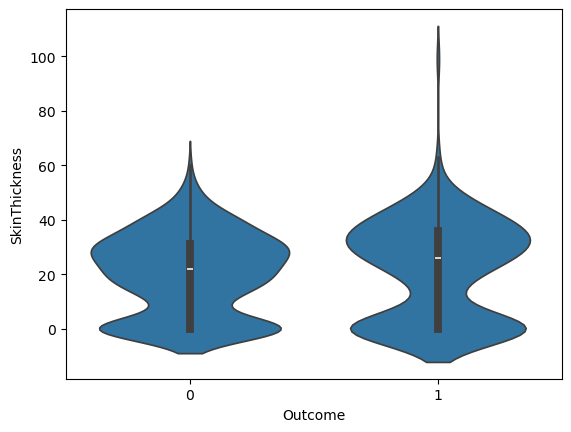

In [69]:
sns.violinplot(x="Outcome", y="SkinThickness", data=df_train)
plt.show()

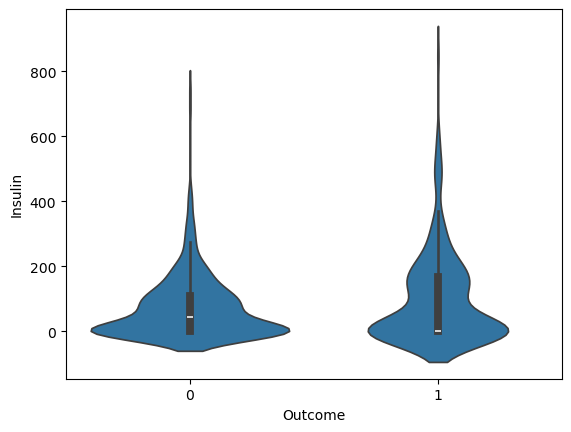

In [70]:
sns.violinplot(x="Outcome", y="Insulin", data=df_train)
plt.show()

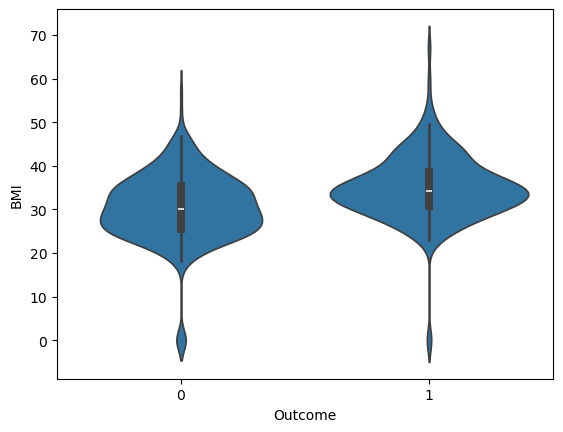

In [71]:
sns.violinplot(x="Outcome", y="BMI", data=df_train)
plt.show()

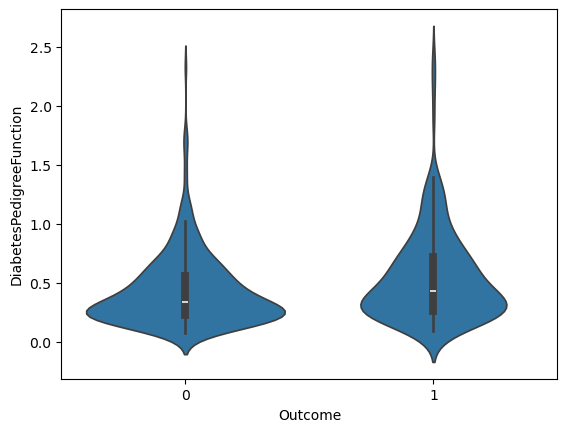

In [72]:
sns.violinplot(x="Outcome", y="DiabetesPedigreeFunction", data=df_train)
plt.show()

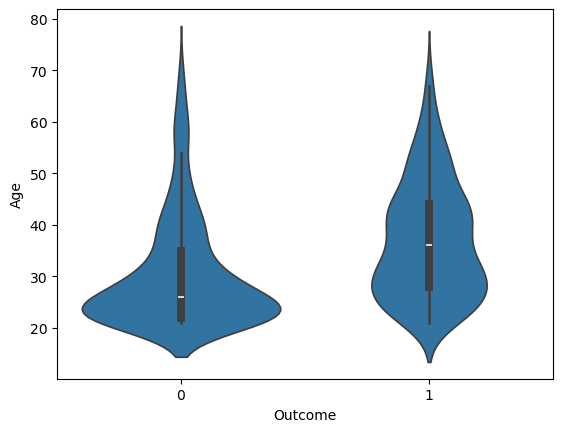

In [73]:
sns.violinplot(x="Outcome", y="Age", data=df_train)
plt.show()

part6

#سوال2
«در این دیتاست ستون categorical متنی که نیاز به One-Hot Encoding یا تبدیل ۰ و ۱ داشته باشد نداریم، بنابراین Encoding انجام نمی‌دهیم.»

In [74]:
#سوال3
df_train.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,10,108,66,0,0,32.4,0.272,42,1
1,5,166,72,19,175,25.8,0.587,51,1
2,3,96,78,39,0,37.3,0.238,40,0
3,8,110,76,0,0,27.8,0.237,58,0
4,0,126,86,27,120,27.4,0.515,21,0
5,5,109,62,41,129,35.8,0.514,25,1
6,5,97,76,27,0,35.6,0.378,52,1
7,1,140,74,26,180,24.1,0.828,23,0
8,2,128,64,42,0,40.0,1.101,24,0
9,7,81,78,40,48,46.7,0.261,42,0


In [75]:
# Question 6

df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               614 non-null    int64  
 1   Glucose                   614 non-null    int64  
 2   BloodPressure             614 non-null    int64  
 3   SkinThickness             614 non-null    int64  
 4   Insulin                   614 non-null    int64  
 5   BMI                       614 non-null    float64
 6   DiabetesPedigreeFunction  614 non-null    float64
 7   Age                       614 non-null    int64  
 8   Outcome                   614 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 43.3 KB


In [76]:
# Question 7

df_val.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [77]:
train_medians = df_train[zero_columns].median()

NameError: name 'zero_columns' is not defined

In [ ]:
# Question 8
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
train_medians = df_train[zero_columns].median()

for col in zero_columns:
    df_val[col] = df_val[col].replace(0, train_medians[col])

# حذف هر NaN باقی‌مونده (اگه بود)
df_val = df_val.dropna().reset_index(drop=True)

print("NaN in Val:", df_val.isnull().sum().sum())
print("Zeros in Val:", (df_val[zero_columns] == 0).sum().sum())
print("Shape:", df_val.shape)


In [ ]:
# Question 9

df_val.head(10)

In [ ]:
# Question 11

df_test.isnull().sum().sum()

In [ ]:
# Question 12
for col in zero_columns:
    df_test[col] = df_test[col].replace(0, train_medians[col])

df_test = df_test.dropna().reset_index(drop=True)

print("NaN in Test:", df_test.isnull().sum().sum())
print("Zeros in Test:", (df_test[zero_columns] == 0).sum().sum())
print("Shape:", df_test.shape)

In [84]:
train_median_dict={"Glucose":df_train.loc[df_train["Glucose"]!=0,"Glucose"].median(),
                "BloodPressure":df_train.loc[df_train["BloodPressure"]!=0,"BloodPressure"].median(),
                "SkinThickness":df_train.loc[df_train["SkinThickness"]!=0,"SkinThickness"].median(),
                "Insulin":df_train.loc[df_train["Insulin"]!=0,"Insulin"].median(),
                "BMI":df_train.loc[df_train["BMI"]!=0,"BMI"].median()}

In [85]:
# Question 13

df_test.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,9,120,72,22,56,20.8,0.733,48,0
1,1,100,66,15,56,23.6,0.666,26,0
2,0,91,80,0,0,32.4,0.601,27,0
3,9,145,80,46,130,37.9,0.637,40,1
4,8,109,76,39,114,27.9,0.640,31,1
5,0,161,50,0,0,21.9,0.254,65,0
6,5,147,75,0,0,29.9,0.434,28,0
7,2,146,76,35,194,38.2,0.329,29,0
8,6,85,78,0,0,31.2,0.382,42,0
9,11,136,84,35,130,28.3,0.260,42,1


In [86]:
train_median_dict={"Glucose":df_train.loc[df_train["Glucose"]!=0,"Glucose"].median(),
                "BloodPressure":df_train.loc[df_train["BloodPressure"]!=0,"BloodPressure"].median(),
                "SkinThickness":df_train.loc[df_train["SkinThickness"]!=0,"SkinThickness"].median(),
                "Insulin":df_train.loc[df_train["Insulin"]!=0,"Insulin"].median(),
                "BMI":df_train.loc[df_train["BMI"]!=0,"BMI"].median()}

In [87]:
# Question 14

df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               77 non-null     int64  
 1   Glucose                   77 non-null     int64  
 2   BloodPressure             77 non-null     int64  
 3   SkinThickness             77 non-null     int64  
 4   Insulin                   77 non-null     int64  
 5   BMI                       77 non-null     float64
 6   DiabetesPedigreeFunction  77 non-null     float64
 7   Age                       77 non-null     int64  
 8   Outcome                   77 non-null     int64  
dtypes: float64(2), int64(7)
memory usage: 5.5 KB


In [88]:
# Question 15

df_train.to_csv("Pima_train_final.csv", index=False)

df_val.to_csv("Pima_val_final.csv", index=False)

df_test.to_csv("Pima_test_final.csv", index=False)